## Abstract

Transformers trained on planetary orbits can predict planet movement with high fidelity under multiple possible 'World models'. Understanding which world model a transformer has learned to represent is an open problem. Here, we apply Equivalent Linear Mapping to precisely characterize how a short-context transformer builds its predictions from two past planetary positions.

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Liu et al. (2026) investigated the world models learned by transformers trained to predict planetary motion. Using linear probes, they found evidence that their transformers learned Keplerian or Newtonian world models depending on inductive biases such as context length. However, while linear probes can reveal what's encoded in a model, they don't necessarily reveal how a model computed its prediction. Here, we open the black box by applying **Equivalent Linear Mapping (ELM)** to rewrite the trained models as an exact per-input linear map. This lets us directly understand how each transformer arrives at its prediction, revealing the underlying learned world model.

## Introduction

The strong performance of foundation models across scientific domains has spurred interest in their internal workings, particularly in the "world models" they are said to learn. Loosely, world models are defined as the internal representation a network builds of the process that generated its training data, which shapes the implicit rules it learns to use to make predictions. Methods that can reliably reveal these learned representations could therefore serve as useful tools for surfacing structure in training data that no explicit supervision targeted.

A popular approach to elucidating world models uses probes (both linear and nonlinear) [Alain & Bengio, 2017; Conneau et al., 2018] to test whether a variable of interest can be decoded from a learned representation. This has been applied extensively to argue that world models emerge in sequence predictors, from board game state in models trained on Othello moves [Li et al., 2023], to linear representations of space and time in large language models [Gurnee & Tegmark, 2024]. However, this inference can be fragile. The success of a probe is contingent on the chosen target and how it is parameterized [see Nanda et al., 2023], and, more fundamentally, a probe reports what is *encoded*, not what is *computed* with [Ravichander et al., 2021]. [Vafa et al. 2025] used a complementary approach which tests whether a networks inductive bias aligns with a world model by fine-tuning it on synthetic tasks derived from that model and measuring its ability to extrapolate consistently. The authors applied this to transformers trained on simulated planetary orbits, finding that a model that predicts planetary trajectories with high accuracy fails to recover Newtonian mechanics when adapted to predict gravitational force vectors, a result they posit is consistent with their models having learned adequate approximations rather than the true (and therefore generalizable) world model. This work leaves several unanswered questions however; why do transformers not learn the true world model, and can they be steered towards doing so? These aims were tackled by the work of [Liu et al., 2026] who explored how inductive biases in model architecture and training affect learned world models in a similar planterary orbit setting. Notably, the authors report that while long-context models appeared to leverage Keplerian ellipse fitting, reducing the context length forced models to encode Newtonian force variables. However, this inference is fully reliant on the sufficiency of linear probes to recover the learned world models. 

Here, we tackle the question of world models with a complementary approach, equivalent linear mapping (ELM), which targets what other methods are blind to, the computation itself. Mechanistic interpretability has shown that transformer computations can, in principle, be read directly from model weights and activations [Elhage et al., 2021], but this work has largely focused on specific circuit-level phenomena rather than inferring world models. ELM makes this exercise tractable by rewriting each trained network as an exact per-input linear map which allows us to read the end-to-end computation mechanism directly from the models' Jacobians. Taking advantage of this simplicity, we build on the work of [Liu et al., 2026] using transformers trained on simulated planetary orbits as a toy system of world model emergence and inference. Taking the Verlet integrator as a reference computation compatible with a Newtonian world model, we ask how closely each network's recovered computation map matches it. We find that despite carrying linearly decodable Newtonian force variables, the short-context transformer of Liu et al. computes a circular-rotation heuristic, a mechanism that works sufficiently well for the one-step prediction training task but does not rely on Newtonian force. We trace this to the input noise the authors inject during training to stabilize model rollouts. Retraining the short-context model without noise yields a network whose input-level operations closely match Verlet integration, consistent with a genuine Newtonian world model. We further show that while linear probes can recover Newtonian force components in both models, they do so by leveraging low variance dimensions in model activation space, which themselves do not seem to be necessary for the emergence of Newtonian force in model predictions. Our analysis represents a worked example of identifying a network's internal computation without internal probing, and of adjudicating among candidate world models against a known ground truth when one is available.


## The Setup

The training data is 2D planetary orbits under an inverse-square force, $\ddot{\mathbf r} = -\,GM\,\mathbf r/|\mathbf r|^{3}$ (units with $GM=1$). The transformer reads a sequence of past positions $\mathbf r_0, \mathbf r_1, \dots$ and predicts the next one, $\hat{\mathbf r}_{t+1}$. Its context length (block size) is the number of past positions it can attend to. Two alternative models can, in principle, be used to fit the training data:

- a **Newtonian** model: estimate the local gravitational force from the last one or two positions and integrate $F = ma$. In this context, this is the “true” world model which captures the generative process behind the data.

- a **Keplerian** model: fit the global ellipse through the observed points and continue along it. While ellipse fitting can work very well for predicting planetary position, it fails to capture the true world model. 


**The data.** We reuse Liu et al.'s data-generation procedure. Each trajectory is a bound elliptical orbit obtained by numerically integrating $\ddot{\mathbf r} = -\,GM\,\mathbf r/|\mathbf r|^{3}$ ($GM = 1$) with `scipy`'s `solve_ivp` at relative and absolute tolerances of $10^{-8}$. Orbits are initialized at perihelion with parameters drawn uniformly: eccentricity $e \in [0, 0.8]$, semi-major axis $a \in [0.5, 2.0]$, and orientation $\theta \in [0, 2\pi]$ , with the initial state rotated by $\theta$. Each trajectory is sampled at 100 equally spaced points, giving sequences of shape $(100, 2)$. The nominal step is $\Delta t = 0.2$, but the generator lays the 100 samples out over $[0, 20]$ with `linspace`, so the true spacing is $20/99 \approx 0.202$, 1% wider. We inherit this from Liu et al.'s generator and use the true spacing wherever we compare the model against a physical formula. Note the eccentricity distribution is broad (uniform up to $e = 0.8$, mean $0.4$): the typical training orbit is appreciably non-circular, which will matter when we characterize what the short-context model actually learns.

**What we train.** We retrain Liu et al.'s model, a small GPT-2-style transformer (a modified nanoGPT), from scratch at the two context lengths that bracket their result: 2 and 100. We train both models using Liu et al.'s noisy-context training (input positions perturbed by Gaussian noise $\sigma = 0.1$) that stabilizes autoregressive prediction. Additionally, we train a noiseless context length 2 model ($\sigma = 0$). Our one departure from their setup is that we disable every bias term as the ELM analysis below needs the network to be a homogeneous linear map at each operating point.

With the models in hand, our first two analyses set up the tools the rest of the pub relies on: (1) the ELM decomposition is exact, so its per-input attributions are trustworthy; and (2) linear probing reproduces the phase transition reported by Liu et al. on these checkpoints.


::: {.callout-note collapse="true" title="Model architecture and training (details)"}

**Architecture.** Each model is a small decoder-only GPT (a bias-free modification of nanoGPT), identical at the two context lengths except for the block size:

- **Depth/width:** 2 pre-norm transformer blocks, 1 attention head, embedding dimension $d_{\text{model}} = 32$ (MLP hidden width $4d = 128$, SiLU activation), for $\approx\!25\text{k}$ parameters total.

- **Continuous I/O (no tokenizer):** each 2D position $\mathbf r_t \in \mathbb{R}^2$ is linearly projected into the 32-dim residual stream, a learned positional embedding $\mathrm{wpe}[t]$ is added, and a final linear head maps the stream back to $\mathbb{R}^2$ to predict the next position. We nonetheless refer to each input position as a token, as is standard for continuous-input transformers.

- **Context length (block size):** 2 or 100.

- **No bias terms:** attention heads, MLP, LayerNorm, and both I/O projections (see ELM section for explanation) are trained with no biases. Standard LayerNorm (scale only), dropout $0$, and no log-position attention scaling ($\alpha = 0$).

**Training.**

- **Data:** 10,000 trajectories for training and 10,000 held out for test, each 100 points long, chopped into sliding (input-window, next-position) pairs.

- **Objective:** mean-squared error on the next-position prediction, one step ahead, with no autoregressive rollout in the loss. At context length 100 every input position is supervised, each against the position that follows it; at context length 2 each training window carries a single target, so only the prediction ($\hat{\mathbf r}{t+1}$) made from the full window $(\mathbf r{t-1}, \mathbf r_t)$ is supervised.

- **Optimizer:** AdamW, learning rate $10^{-3}$ decayed by $10\times$ at the halfway point, weight decay $0$, batch size $128$, $20{,}000$ steps, seed $1$.

- **Noisy-context augmentation:** input positions are perturbed with Gaussian noise $\mathcal{N}(0, \sigma^2)$ during training. We train a noisy short-context model ($\sigma = 0.1$, following Liu et al.) and a noiseless one ($\sigma = 0$) at block size 2, plus a noisy long-context model ($\sigma = 0.1$, block size 100).

The architecture, weight initialization, and data-generation procedure follow Liu et al. (arXiv:2602.06923); disabling the bias terms is our only architectural change. Full definitions are in `src/analysis/model.py` and `src/analysis/training.py`.

:::


In [1]:
#| code-fold: true
#| output: false
import io
import os
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt

from analysis.model import load_from_checkpoint
from analysis.elm import apply_figure_style

apply_figure_style()   # publication matplotlib defaults; must precede the first figure

torch.set_default_dtype(torch.float64)   # ELM reconstruction is exact only at float64

CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ, NOISE_SCALE, SEED = 10000, 0.1, 0

# Sample spacing of the trajectories. NOT the nominal 0.2: the upstream generator
# samples with t_eval = linspace(0, num_points*dt, num_points), so 100 points over
# [0, 20] land 20/99 apart. Used wherever we compare the model to a physical formula.
DT = 20 / 99
CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

with contextlib.redirect_stdout(io.StringIO()):
    model_bs2,   _ = load_from_checkpoint(CKPT_BS2,   device='cpu'); model_bs2.eval()
    model_bs100, _ = load_from_checkpoint(CKPT_BS100, device='cpu'); model_bs100.eval()


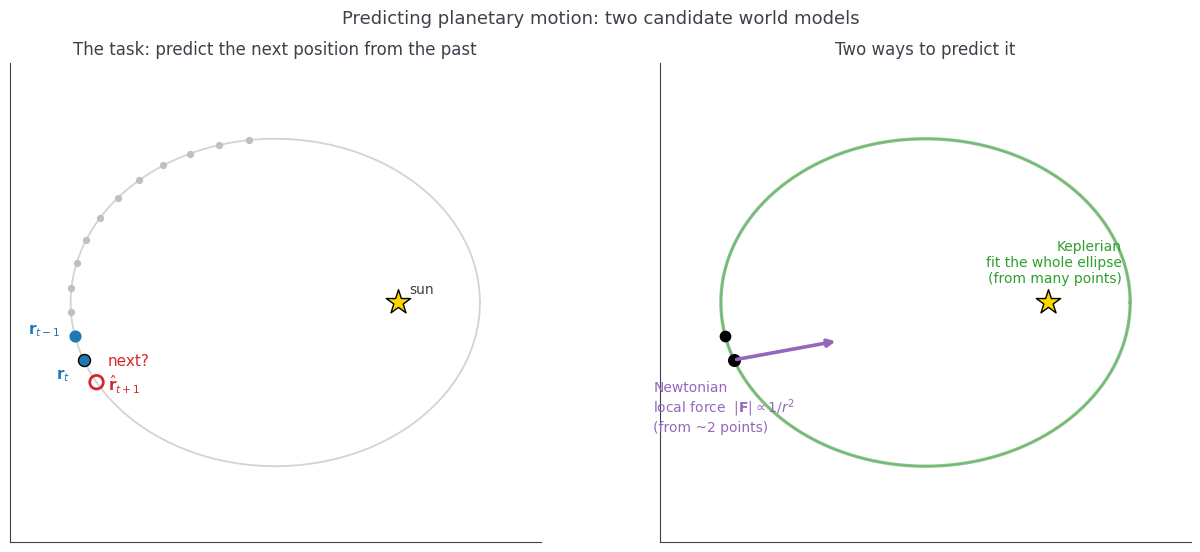

In [2]:
#| label: fig-setup
#| fig-cap: "Schematic of the prediction task and the two candidate world models. Left: the transformer sees past positions along an orbit, the two most recent in blue, and predicts the next one. Right: a Newtonian rule estimates the local inverse-square force from the last two positions and integrates it; a Keplerian rule fits the global ellipse through many points and continues along it."
#| code-fold: true
_a, _e = 1.35, 0.6; _b = _a*np.sqrt(1-_e**2); _c = _a*_e
_E = np.linspace(0, 2*np.pi, 300); _ex, _ey = _a*np.cos(_E), _b*np.sin(_E); _sun = np.array([_c, 0.0])
_Es  = np.linspace(1.7, 3.5, 13)
_pts = np.stack([_a*np.cos(_Es), _b*np.sin(_Es)], 1)
_rp, _rt = _pts[-2], _pts[-1]
_En = 2*_Es[-1] - _Es[-2]; _rn = np.array([_a*np.cos(_En), _b*np.sin(_En)])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
for ax in (axA, axB):
    ax.plot(_ex, _ey, color='lightgray', lw=1.3, zorder=0)
    ax.scatter(*_sun, marker='*', s=340, color='gold', edgecolor='k', zorder=6)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(-_a-0.4, _a+0.4); ax.set_ylim(-_b-0.5, _b+0.5)
axA.scatter(_pts[:-2, 0], _pts[:-2, 1], s=18, color='silver', zorder=3)
axA.scatter(*_rp, s=60, color='tab:blue', zorder=4); axA.scatter(*_rt, s=75, color='tab:blue', edgecolor='k', zorder=4)
axA.scatter(*_rn, s=95, facecolor='none', edgecolor='tab:red', lw=2, zorder=5)
axA.annotate(r'$\mathbf{r}_{t-1}$', _rp, textcoords='offset points', xytext=(-34, 2), color='tab:blue', fontsize=11)
axA.annotate(r'$\mathbf{r}_t$', _rt, textcoords='offset points', xytext=(-20, -14), color='tab:blue', fontsize=11)
axA.annotate('next?\n' r'$\hat{\mathbf{r}}_{t+1}$', _rn, textcoords='offset points', xytext=(8, -6), color='tab:red', fontsize=11)
axA.annotate('sun', _sun, textcoords='offset points', xytext=(8, 6), fontsize=10)
axA.set_title('The task: predict the next position from the past', fontsize=12)
axB.scatter(*_rp, s=55, color='k', zorder=4); axB.scatter(*_rt, s=70, color='k', edgecolor='k', zorder=4)
_d = _sun - _rt; _d = _d/np.linalg.norm(_d)*0.7
axB.annotate('', xy=_rt + _d, xytext=_rt, arrowprops=dict(arrowstyle='-|>', color='tab:purple', lw=2.6), zorder=5)
axB.annotate('Newtonian\nlocal force  ' r'$|\mathbf{F}|\propto 1/r^2$' '\n(from ~2 points)', _rt, textcoords='offset points', xytext=(-58, -52), color='tab:purple', fontsize=10)
axB.plot(_ex, _ey, color='tab:green', lw=2.4, alpha=0.55, zorder=2)
axB.annotate('Keplerian\nfit the whole ellipse\n(from many points)', (_ex.max(), 0), textcoords='offset points', xytext=(-6, 14), color='tab:green', fontsize=10, ha='right')
axB.set_title('Two ways to predict it', fontsize=12)
fig.suptitle('Predicting planetary motion: two candidate world models', fontsize=13)
fig.tight_layout(); plt.show()


## Applying the ELM decomposition

Once we have a trained model, we can apply ELM to it to assess how it computes its positional prediction from the input coordinates. A transformer is nonlinear, so in general, no single matrix maps its input to its output. But the nonlinearity is concentrated in a few input-dependent transformations, such as how strongly each vector is normalized, which neurons the gates switch on, and where attention looks. ELM freezes those choices at the values they take for one specific input $x^*$ and detaches them from the gradient (Golden 2026). For that input, the network then behaves as an exact linear map, which we can read off as a set of detached Jacobian matrices $J_i(x^*)$ and interpret directly:

$$y^* \;=\; \sum_i J_i(x^*)\, x_i^* \qquad\text{(exact at }x^*\text{).}$$

This reconstruction is degree-1 homogeneous; it contains no additive constant. We therefore train all models with bias terms disabled, which ensures the map is genuinely homogeneous and the reconstruction is exact to float64 precision (~1e-16) rather than approximate.

Three nonlinearities are frozen: the LayerNorm scale, the SiLU gate, and the attention weights, after which the input-to-output map is exactly linear-homogeneous at $x^*$. The details of how each is detached are below.

::: {.callout-note collapse="true" title="How the three nonlinearities are detached"}
- **LayerNorm denominator** — the RMS normalization constant $\sigma(x^*)$ is frozen, so the gradient sees only the linear numerator $x / \sigma(x^*)$. The mean-centering $(x - \bar{x})$ is *kept* in the gradient path because it is itself linear (multiplication by $C = I - \mathbf{1}\mathbf{1}^\top/d$).
- **SiLU gate** — $\text{SiLU}(x) = x\cdot\sigma(x)$ is linearised as $x\cdot\sigma(x^*)$, freezing the sigmoid factor so only the linear $x$ carries gradient.
- **Attention weights** — both the query $Q$ and key $K$ are detached before the score computation, freezing the full attention matrix $A(x^*)$; gradient flows only through the value path $V = W_V x$.
:::

**Content vs. positional split.** Here, the output is the predicted position and the input tokens are the observed ones, $y^* = \hat{\mathbf r}_{t+1}$ and $x_i = \mathbf r_i$. The transformer architecture used by Liu et al. adds a positional embedding to each token, $h_i = W_{\text{in}}\,\mathbf r_i + \mathrm{wpe}[i]$, the one constant offset we do not remove from the model. To get around this, we differentiate downstream of that embedding sum, treating $h_i$ as the variable, which is exactly linear after detachment and splits cleanly into a part driven by the input positions and a part driven by the (input-independent[^2]) positional embeddings:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{\sum_i J_{h,i}\, W_{\text{in}}\, \mathbf r_i}_{\text{content}}
\;+\; \underbrace{\sum_i J_{h,i}\, \mathrm{wpe}[i]}_{\text{positional}}$$

Write $J_i = J_{h,i}\,W_{\text{in}}$ for the $2\times2$ content blocks (in $(x,y)$ coordinates) and $\mathbf P$ for the positional embedding term sum. The short-context model sees a window of two positions, so the identity we interpret from here on is

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{J_t\,\mathbf r_t \;+\; J_{t-1}\,\mathbf r_{t-1}}_{\text{content}} \;+\; \underbrace{\mathbf P}_{\text{positional}}$$

one $2\times2$ block per input position, plus one positional vector.

**Verification.** @fig-elm-recon plots the model's true forward output against the ELM reconstruction for the last output token, at both context lengths. The points lie on the identity line with relative error $\sim 10^{- 16}$ (machine precision), verifying that the Detached Jacobian is an exact stand-in for the model at $x^*$. This result confirms the per-token attributions used in the rest of this pub are trustworthy.

[^2]:The positional embeddings are a learned static vector per position, invariant with respect to inputs in (x,y) coordinates during inference, which is what lets us split them off from the content terms. The positional *contribution* $\mathbf P$ is not input-independent, though, because the detached Jacobians $J_{h,i}$ vary with the operating point.


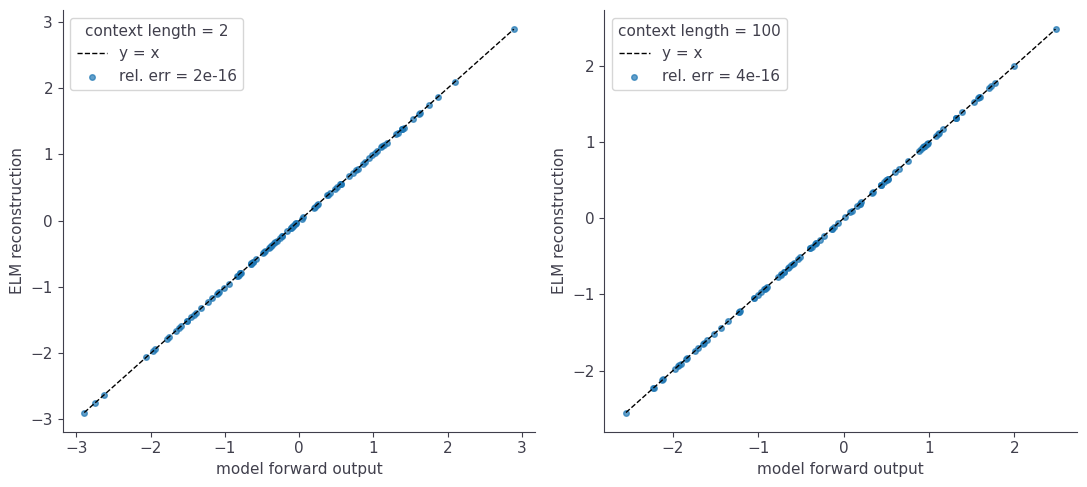

In [3]:
#| label: fig-elm-recon
#| fig-cap: "ELM reconstruction against the model's own forward output for the last position, at context lengths 2 and 100. One point per window; the dashed line is the identity. The legend gives the median relative error between the two."
#| code-fold: true
from analysis.elm import reconstruction_scatter

mv_2,   ev_2   = reconstruction_scatter(model_bs2,   2,   n_windows=50, seed=SEED)
mv_100, ev_100 = reconstruction_scatter(model_bs100, 100, n_windows=50, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mv, ev, label in [(axes[0], mv_2,   ev_2,   'context length = 2'),
                          (axes[1], mv_100, ev_100, 'context length = 100')]:
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo, hi = float(min(mv.min(), ev.min())), float(max(mv.max(), ev.max()))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
    ax.scatter(mv, ev, s=16, c='tab:blue', alpha=0.7, label=f'rel. err = {err:.0e}')
    ax.set_xlabel('model forward output')
    ax.set_ylabel('ELM reconstruction')
    ax.legend(title=label)
fig.tight_layout()
plt.show()


## Replicating linear probe results

Now that we have an ELM-compatible version of the short- and long-context models, we need to verify that our retrained transformers reproduce the probing results reported by Liu et al. We repeat the probing analysis used to generate Figure 6 by the authors, probing each layer of the model for physical quantities compatible with either Newtonian or Keplerian models, reporting the best $R^2$ value. The Newtonian targets are local, the gravitational force $\mathbf F = -\mathbf r/|\mathbf r|^3$ and its components $F_x, F_y$, computable from the current position alone. The Keplerian targets describe the whole orbit: the semi-major and semi-minor axes $a, b$ (its size and shape), and the Laplace–Runge–Lenz vector $\mathbf A = (A_x, A_y)$, which points along the major axis toward perihelion and so encodes the orbit's orientation and eccentricity.


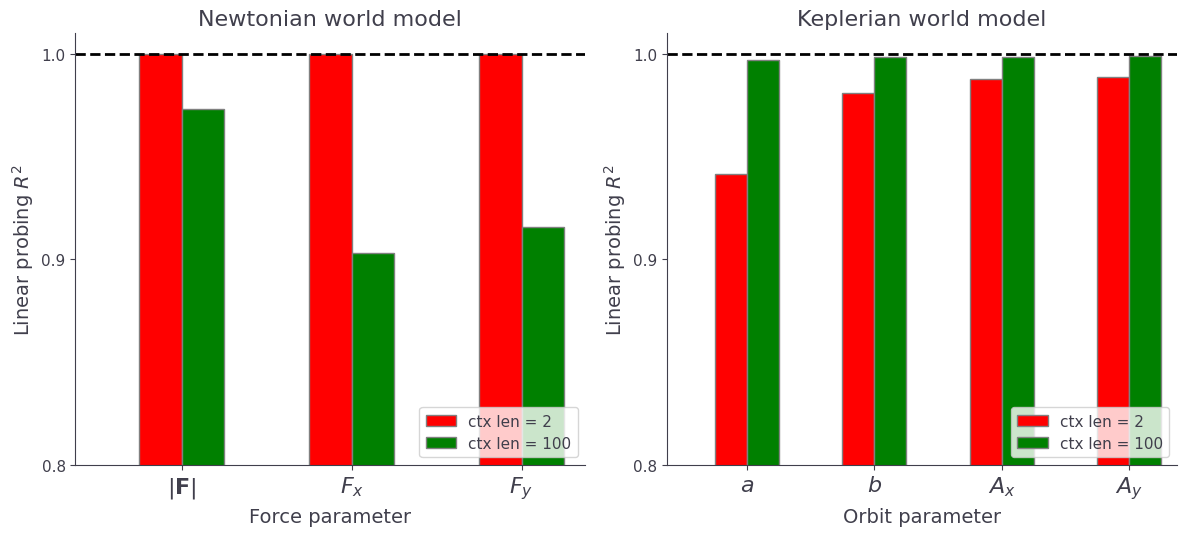

In [4]:
#| label: fig-phase-transition
#| fig-cap: "Best-layer linear-probing R^2 at the last position, for context length 2 (red) and context length 100 (green). Left: the Newtonian targets, force magnitude |F| and its components F_x and F_y. Right: the Keplerian targets, the semi-major and semi-minor axes a and b and the two components of the Laplace-Runge-Lenz vector."
#| code-fold: true
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import probe_model, best_r2

with contextlib.redirect_stdout(io.StringIO()):
    trajs    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=NUM_TRAJ))
    o_params = load_orbital_params(DATA_DIR, num_trajectories_needed=NUM_TRAJ)
    newton_2,   kepler_2   = probe_model(model_bs2,   trajs, o_params, 2,   n_probe=1000, seed=SEED)
    newton_100, kepler_100 = probe_model(model_bs100, trajs, o_params, 100, n_probe=1000, seed=SEED)

NEWTON = [('F_magnitude', r'$|\mathbf{F}|$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, xlabel, items, p2, p100) in zip(axes, [
        ('Newtonian world model', 'Force parameter', NEWTON, newton_2, newton_100),
        ('Keplerian world model', 'Orbit parameter', KEPLER, kepler_2, kepler_100)]):
    targets = [t for t, _ in items]; ticklab = [l for _, l in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25; br1 = np.arange(len(targets))
    b1 = ax.bar(br1,      r2_2,   bw, color='r', edgecolor='grey', label='ctx len = 2')
    b2 = ax.bar(br1 + bw, r2_100, bw, color='g', edgecolor='grey', label='ctx len = 100')
    ax.plot([-0.5, len(targets) - 0.5], [1, 1], '--', color='black', lw=2)
    ax.set_xlim(-0.5, len(targets) - 0.5); ax.set_ylim(0.8, 1.01); ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab, fontsize=16)
    ax.set_xlabel(xlabel, fontsize=14); ax.set_ylabel(r'Linear probing $R^2$', fontsize=14)
    ax.set_title(title, fontsize=16); ax.legend(handles=[b1, b2], fontsize=11, loc='lower right')
fig.tight_layout(); plt.show()


@fig-phase-transition shows that our retrained models exhibit the same probing characteristics reported by Liu et al. At context length 2, probing recovers Newtonian force components almost perfectly and above the orbital-geometry variables. At context length 100 that ranking flips, with the geometry variables best predicted. Notably, every target stays decodable at $R^2$>0.9 at both context lengths, the "transition" is a shift in which world model is best encoded, not a presence/absence switch[^1]. This is the same overall result Liu et al. identified, and our checkpoints reproduce it (consistent within run-to-run variance).

Confident that our models are behaving as expected, we now focus on using ELM to understand how input coordinates are combined to generate predictions in the short-context (blocksize = 2) model. We restrict our analyses to this model for two reasons: 1) the limited number of input tokens makes it easier to interpret a smaller number of per-token Jacobians, and 2) the short context model is the one that appears to learn the 'correct' Newtonian world model according to linear probing and is thus most interesting to unpack.

[^1]: We construct our probes on in-sample windows following the codebase of Liu et al. Out of sample probing results provide a similar picture with the world model phase transition becomes more stark. 

## Inside the short-context model

The probes tell us we can decode force variables using a linear transformation of the model's latent representations, but does the short-context model actually use Newtonian mechanics to make its predictions? With ELM, we can read out the actual computation: how the model turns the two positions it sees, $\mathbf r_{t-1}$ and $\mathbf r_t$, into its prediction $\hat{\mathbf r}_{t+1}$.

Here, we must address what it would mean for this computation to reflect a genuinely learned Newtonian world model. Since the training task is to predict a single future position, many heuristics can approximate it well without implementing the underlying physics. Simply copying the last position (persistence: $\hat{\mathbf r}_{t+1} = \mathbf r_t$) already achieves high $R^2$, since consecutive positions are close. More subtly, geometrically aware heuristics such as rotations could reproduce the *appearance* of a central force and even produce hidden states from which force components are linearly decodable, without computing the force law itself. Predictive accuracy, and even a passing linear probe, therefore, cannot establish that a model has learned Newtonian gravity. Our criterion is instead structural: does the recovered computation match that of a Newtonian mechanics-derived integrator? Since ELM recovers the exact linear combination of the two input positions used to form the prediction, we can compare it directly to a textbook solution of Newtonian orbital mechanics. Our reference is the second-order Verlet integrator:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{2\,\mathbf r_t - \mathbf r_{t-1}}_{\text{inertial}}
\;+\;\underbrace{\Delta t^{2}\mathbf a(\mathbf r_t)}_{\text{gravitational acceleration}},
\qquad
\mathbf a(\mathbf r) \;=\; \ddot{\mathbf r} \;=\; -\,\frac{\mathbf r}{|\mathbf r|^{3}}$$

::: {.callout-note collapse="true" title="Deriving the Verlet integrator"}
Newton's second law gives the equation of motion
$\ddot{\mathbf r} = \mathbf a(\mathbf r)$, which for our system is
$\ddot{\mathbf r} = -\mathbf r/|\mathbf r|^3$. To integrate this forward in time from
two known positions, expand $\mathbf r$ as a Taylor series in both directions:

$$\mathbf r(t+\Delta t) = \mathbf r_t + \mathbf v_t\Delta t
+ \tfrac{1}{2}\mathbf a_t\Delta t^2 + O(\Delta t^3)$$

$$\mathbf r(t-\Delta t) = \mathbf r_t - \mathbf v_t\Delta t
+ \tfrac{1}{2}\mathbf a_t\Delta t^2 + O(\Delta t^3)$$

Adding the two equations cancels the velocity term exactly, the odd-power terms
cancel and the even-power terms reinforce:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{2\,\mathbf r_t - \mathbf r_{t-1}}_{\text{inertial}}
\;+\;\underbrace{\Delta t^{2}\,\mathbf a(\mathbf r_t)}_{\text{gravitational acceleration}},
\qquad
\mathbf a(\mathbf r) \;=\; -\,\frac{\mathbf r}{|\mathbf r|^{3}}$$
:::

The inertial part $2\,\mathbf r_t - \mathbf r_{t-1}$ is constant-velocity coasting, rewritten as $\mathbf r_t + (\mathbf r_t - \mathbf r_{t-1})$, it reads "current position plus the last step's displacement." The final term is the small gravitational kick: the acceleration $\mathbf a$ of the Setup's equation of motion, evaluated at the current position and held constant over one step of length $\Delta t$. A genuine force integrator therefore, weights its two inputs by $(c_{t-1}, c_t) = (-1, 2)$ before the force correction. We call $(-1, 2)$ the **inertial point**. The Verlet integrator is the natural reference for a two-token model. With only two past positions available, one can estimate position, velocity, and acceleration, exactly the three quantities Verlet uses, but not the higher-order derivatives (jerk, snap) needed by more accurate multi-evaluation integrators such as RK4.

How do we determine if the model is behaving like a Verlet integrator? While the gravitational term could be captured by any term in the ELM sum, inertia has to be encoded in the two content Jacobians because inertial extrapolation only works when applied to the coordinates of the previous planetary positions. Compounding this, inertia should also dominate the update in most orbital positions. **Consequently, a first-pass test for Verlet structure is to check whether the model carries the inertial point weights in the two relevant content Jacobians.** Each per-token block $J$ is $2\times2$, and its isotropic part $c = \mathrm{tr}(J)/D$ (here $D=2$) is the scalar by which that input position is uniformly scaled into the prediction. A genuine force integrator has to land *near* $(c_{t-1}, c_t) = (-1, 2)$.

This isotropic test probes the inertial backbone; whether the small residual correction is the Newtonian force term is a separate question we take up in downstream analyses.

In [5]:
#| code-fold: true
#| output: false
# Mechanistic analysis of the short-context (noise=0.1) model. Reuses the model and
# constants loaded in the intro setup; only adds the analysis helpers.
from analysis import elm as NT
from analysis.data import load_trajectories

model = model_bs2                 # the bs=2, noise=0.1 model from the intro

BLOCK_SIZE    = 2
N_WINDOWS     = 900               # Jacobian-based analyses (expensive; ~14 s per model).
                                  # 900 keeps ~180 windows per radius bin in the binned
                                  # panel below, enough for its bootstrap CIs to separate
                                  # the terms from the ideal kick.
N_WINDOWS_BEH = 4000              # behavioural analyses (cheap forward passes)
SPLIT  = 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # 50/50 train/test split, by trajectory

def load_split_trajectories(n, data_dir=DATA_DIR, offset=None):
    offset = OFFSET if offset is None else offset
    with contextlib.redirect_stdout(io.StringIO()):
        trajs = np.asarray(load_trajectories(data_dir, num_trajectories_needed=offset + n))
    return trajs[offset:offset + n]


In [6]:
#| code-fold: true
#| output: false
# Per-token Jacobian blocks over N_WINDOWS real-orbit windows (slow; ~1-2 min).
# collect_terms also returns the size of each term in the ELM sum (the two
# content contributions and the positional one), used in the right-hand panel below.
all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
    model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]


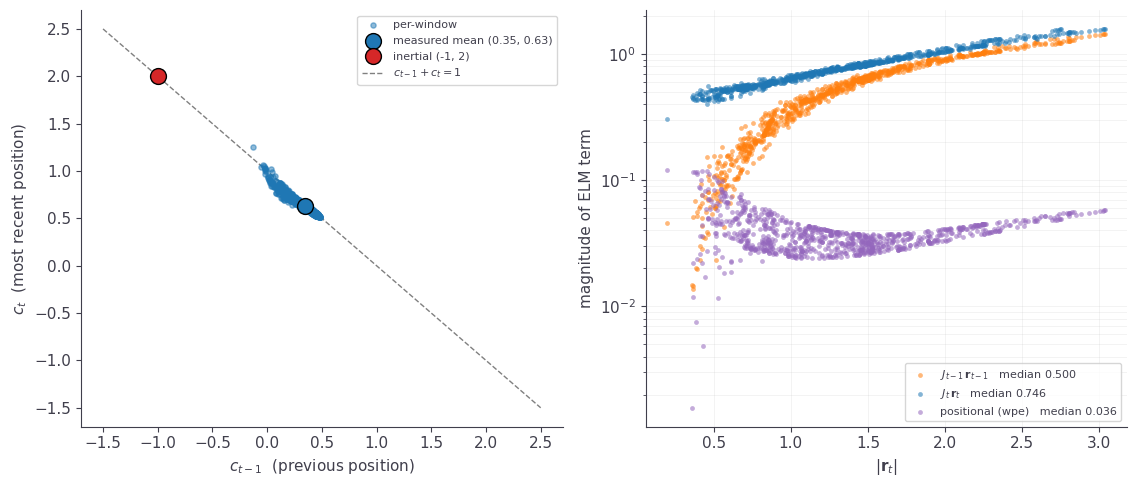

In [7]:
#| label: fig-verlet-coeff
#| fig-cap: "Left: the noisy short-context model in (c_{t-1}, c_t) space, where c = tr(J)/D is the isotropic part of a content Jacobian and gives the scalar weight placed on that input position. One point per window in blue, with the mean marked; the red circle is the inertial point (-1, 2) of a Verlet integrator, and the dashed line is c_{t-1} + c_t = 1. Right: the magnitude of each of the three terms in the ELM sum for the same windows, against |r_t|, on a log axis."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
NT.plot_coefficient_plane(axes[0], coeffs)

# Right panel: how big is each term in the ELM sum?  The coefficient analysis on
# the left uses the content Jacobians only, so show what the omitted positional
# term is worth alongside them.
NT.plot_term_magnitudes(axes[1], content, positional, radius)

fig.tight_layout()
plt.show()


@fig-verlet-coeff shows the content Jacobians do not sit near the inertial point for any sampled prediction windows. Rather, the model's two positive weights make its prediction a weighted average of its inputs. So it is not doing textbook Newtonian integration. To better understand how the model computes its prediction, we also plotted the absolute magnitudes of the three vectors that the ELM identity sums (the two content terms and the total positional term) against the current radius. This view reveals that the most recent token dominates the prediction at small radii, whereas the two content terms become comparable at larger radii. The positional term is tiny across the whole distribution, a couple of percent of the prediction. The massive overweighting of the most recent position further confirms a lack of Verlet-like computation in the model.

If the model is not approximating a Newtonian integrator, which internal logic has it arrived at to make predictions? A guess can be made by inspecting the average of the entire Jacobian block (of both tokens) for a small sample of predictions. @fig-jacobian-rotation shows the averaged per-token blocks: both look like scaled rotation matrices containing equal diagonals and equal-and-opposite off-diagonals[^3], i.e. $J \approx c\,R(\theta)$. The model does not push $\mathbf r_t$ forward rather it likely turns it.

[^3]:Note that this rotational structure emerges so cleanly because all simulated orbits have an anti-clockwise direction, so the off diagonal sign changes do not cancel out


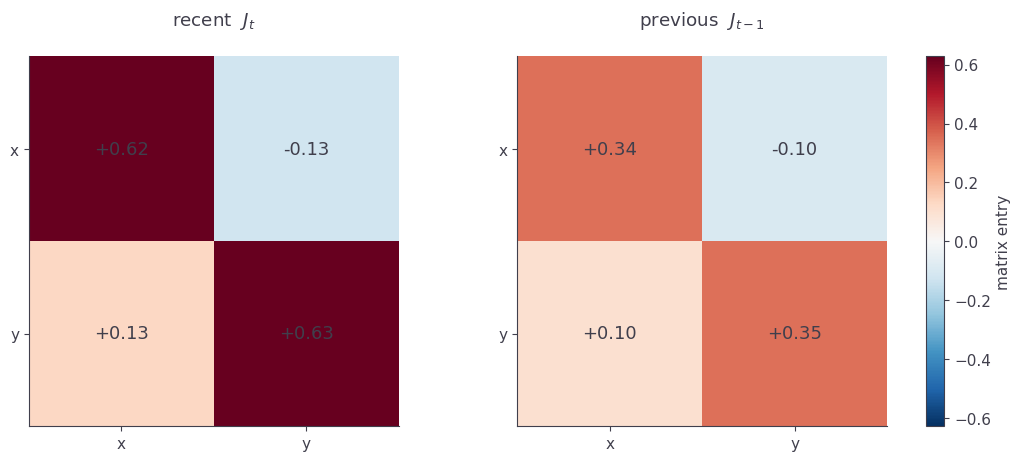

In [8]:
#| label: fig-jacobian-rotation
#| fig-cap: "The two content Jacobian blocks of the noisy short-context model, averaged over windows and drawn as heatmaps with each matrix entry annotated. Panel titles give the scale and angle of the nearest scaled rotation, J ~ s R(theta)."
#| code-fold: true
from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
ds_r, a_r, ang_r, score_r = rotation_decompose(all_blocks[:, T-1])
ds_p, a_p, ang_p, score_p = rotation_decompose(all_blocks[:, T-2])
w_r    = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
radius = np.linalg.norm(w_r[:, T-1, :], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

vmax = max(abs(mean_recent).max(), abs(mean_prev).max())
sc_r, _, angm_r, _ = rotation_decompose(mean_recent)
sc_p, _, angm_p, _ = rotation_decompose(mean_prev)

for ax, M, name, sc, ang in [
    (axes[0], mean_recent, r'recent  $J_t$',       sc_r, angm_r),
    (axes[1], mean_prev,   r'previous  $J_{t-1}$', sc_p, angm_p)
]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['x', 'y']); ax.set_yticklabels(['x', 'y'])
    ax.set_title(f'{name}\n')

fig.colorbar(im, ax=axes.tolist(), fraction=0.046, pad=0.04, label='matrix entry')
plt.show()


We can test this more formally by decomposing the linear transformations encoded by the content Jacobians. A $2\times2$ matrix has four degrees of freedom, which map onto four basis matrices that are mutually orthogonal under the Frobenius inner product $\langle A, B\rangle = \mathrm{tr}(A^\top B)$:

$$J = \underbrace{c \begin{bmatrix}1&0\\0&1\end{bmatrix}}_{\text{isotropic}} +
      \underbrace{a \begin{bmatrix}0&-1\\1&0\end{bmatrix}}_{\text{rotation}} +
      \underbrace{g_1 \begin{bmatrix}1&0\\0&-1\end{bmatrix}}_{\text{axis shear}} +
      \underbrace{g_2 \begin{bmatrix}0&1\\1&0\end{bmatrix}}_{\text{diagonal shear}}$$

The four coefficients are read directly off the matrix entries:

$$c = \frac{J_{00} + J_{11}}{2}, \quad
a   = \frac{J_{10} - J_{01}}{2}, \quad
g_1 = \frac{J_{00} - J_{11}}{2}, \quad
g_2 = \frac{J_{01} + J_{10}}{2}$$

Geometrically each component acts differently on a vector $\mathbf r$:

- **Isotropic** $c$: uniform scaling — pushes radially inward or outward equally in all directions (already used in our test for inertia).

- **Rotation** $a$: rotates $90°$ and scales — a pure turn with no stretching.

- **Axis shear** $g_1$: stretches along $x$ and compresses along $y$ (or vice versa) — deforms without rotating.

- **Diagonal shear** $g_2$: stretches along the $45°$ diagonal and compresses the perpendicular — a second independent shear mode.

With this full decomposition in hand, we calculate a "rotation score":

$$\frac{a^2}{a^2 + g_1^2 + g_2^2}$$

This score has a natural interpretation, it is the fraction of the *direction-changing* action (everything except the isotropic scale) that is a clean rotation rather than a shear distortion. A score near 1 means the block turns vectors without deforming them while a score near 0 means shear dominates. If the model has learned a rotation-based strategy we expect this score to be near 1 for both tokens, shear near zero, and the generator coefficient $a$ to track the gravitational acceleration magnitude across the orbit.


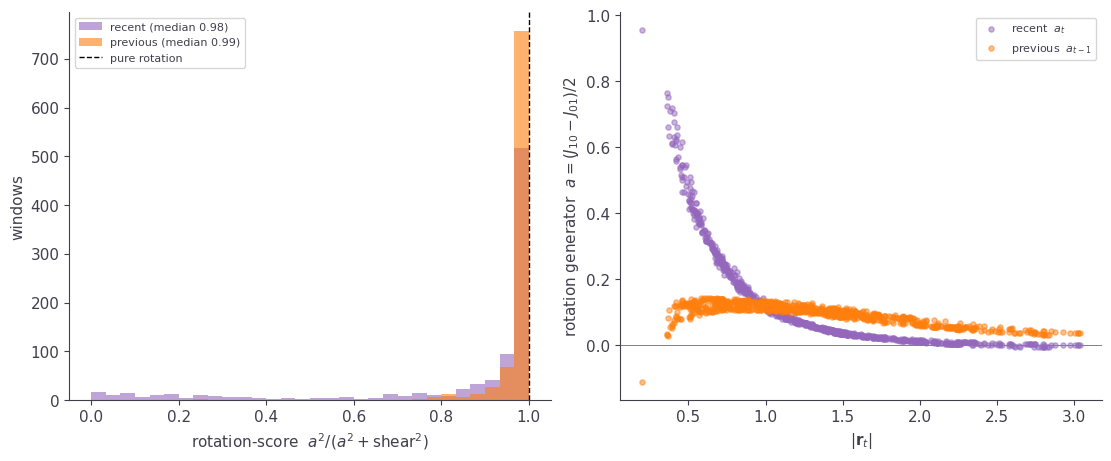

In [9]:
#| label: fig-rotation-generators
#| fig-cap: "Per-window rotation structure of the noisy short-context model's two content blocks. Left: distribution of the rotation score a^2/(a^2 + g_1^2 + g_2^2), the fraction of each block's direction-changing action that is rotation rather than shear. Right: the rotation generator a = (J_10 - J_01)/2, the signed strength of the block's sideways push, against |r_t|. Recent block in purple, previous block in orange."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# Left — rotation score histogram
ax = axes[0]
ax.hist(score_r, bins=30, range=(0, 1), color='tab:purple', alpha=0.6,
        label=f'recent (median {np.median(score_r):.2f})')
ax.hist(score_p, bins=30, range=(0, 1), color='tab:orange', alpha=0.6,
        label=f'previous (median {np.median(score_p):.2f})')
ax.axvline(1, color='k', ls='--', lw=1, label='pure rotation')
ax.set_xlabel(r'rotation-score  $a^2/(a^2+\mathrm{shear}^2)$')
ax.set_ylabel('windows')
ax.legend(fontsize=8, loc='upper left')

# Right — rotation GENERATOR a = (J21 - J12)/2, vs radius
ax = axes[1]
ax.axhline(0, color='gray', lw=0.7)
ax.scatter(radius, a_r, s=14, alpha=0.5, color='tab:purple', label=r'recent  $a_t$')
ax.scatter(radius, a_p, s=14, alpha=0.5, color='tab:orange', label=r'previous  $a_{t-1}$')
ax.set_xlabel(r'$|\mathbf{r}_t|$')
ax.set_ylabel(r'rotation generator  $a=(J_{10}-J_{01})/2$')
ax.legend(fontsize=8)

plt.show()


@fig-rotation-generators (left) shows the rotation-score sits near 1 for both tokens implying each block is a near-pure scaled rotation, not a shear or reflection. @fig-rotation-generators (right) demonstrates that the generator *a* scales with radius, for the more recent planetary position, suggesting that the model might be adjusting the rotation to match gravitational force while at larger radii the prediction beceomes a more even blend of both plantery position coordinates. Together with our results in @fig-verlet-coeff we now have confirmation that the model heavily leans on the current planet position at small radii, and applies a rotational transformation to it that scales with gravitational acceleration. The precise results of the scaled rotation will depend both on the generator and isotropic components (and how their effects are combined across the two tokens). To avoid this complexity, we next use a behavioral test to further test the rotation hypothesis.


### The noisy short-context model runs a local circular-orbit heuristic

Inspecting the Jacobians suggests the model turns $\mathbf r_t$, but what sets the angle? Kepler's second law (a planet sweeps equal areas in equal times) fixes the per-step angle of a real orbit to $\Delta\theta = L_z\,\Delta t / r^2$, where $L_z$ is the angular momentum, the conserved rate at which the position vector sweeps out area. So the true angle should grow like $1/r^2$ (faster near the sun) but also scale with $L_z$ (which differs from orbit to orbit). Our sequences carry positions and not velocities, so we estimate the numerator of that expression directly from the in-window displacement, $L_z\,\Delta t \approx \mathbf r_t \times (\mathbf r_t - \mathbf r_{t-1})$ — the quantity that actually sets the per-step angle. Below we use a behavioral test to compare the model's per-step rotation against both, and against the radial in-and-out motion a real orbit undergoes.


In [10]:
#| code-fold: true
#| output: false
# Behavioural rotation statistics over many cheap forward passes.
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)


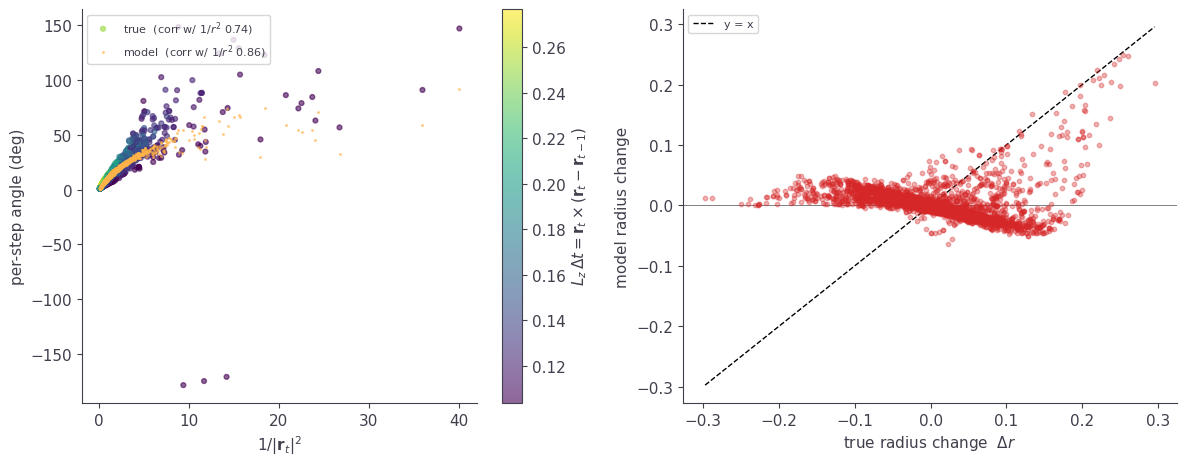

In [11]:
#| label: fig-kepler2
#| fig-cap: "Left: per-step rotation angle against 1/|r_t|^2, for the true orbit and for the model. Points are coloured by L_z dt = r_t x (r_t - r_{t-1}), the numerator of the per-step angle under Kepler's second law, estimated from the in-window displacement because the sequences carry positions rather than velocities. Right: the true per-step change in radius against the model's, with the identity dashed."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: per-step angle vs 1/r^2
ax = axes[0]
Lz_dt, inv_r2 = behav['Lz_dt'], behav['inv_r2']
at, am = np.degrees(behav['ang_true']), np.degrees(behav['ang_model'])
vlo, vhi = float(np.nanpercentile(Lz_dt, 2)), float(np.nanpercentile(Lz_dt, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz_dt, cmap='viridis', vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax); cb.set_label(r'$L_z\,\Delta t = \mathbf{r}_t \times (\mathbf{r}_t - \mathbf{r}_{t-1})$')
ax.set_xlabel(r'$1/|\mathbf{r}_t|^2$'); ax.set_ylabel('per-step angle (deg)')
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dtr, dmr = behav['dr_true'], behav['dr_model']
lo, hi = float(min(dtr.min(), dmr.min())), float(max(dtr.max(), dmr.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dtr, dmr, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change  $\Delta r$'); ax.set_ylabel(r'model radius change')
ax.legend(fontsize=8)

fig.tight_layout(); plt.show()


Two things stand out in @fig-kepler2. The model's rotation angle does indeed monotonically grow with $1/r^2$ (i.e. it speeds up near the sun), but unlike the true orbit, it's a single tight curve which ignores angular momentum (the orange points show little vertical spread, while the true points fan out by colour). Moreover, the model barely changes the radius step-to-step (mostly encoding a small bias towards shrinking the radius), roughly keeping the planet on a circular orbit. Together, these results suggest the model isn't tracking the real orbit; instead, it treats each step as if the planet were on a local circular orbit of the current radius. A circular orbit at radius $r$ sweeps $\Delta\theta = \Delta t / r^{3/2}$ per step (with $GM=1$). If that is the heuristic, the model's rotation should match this curve, a prediction we can also test.


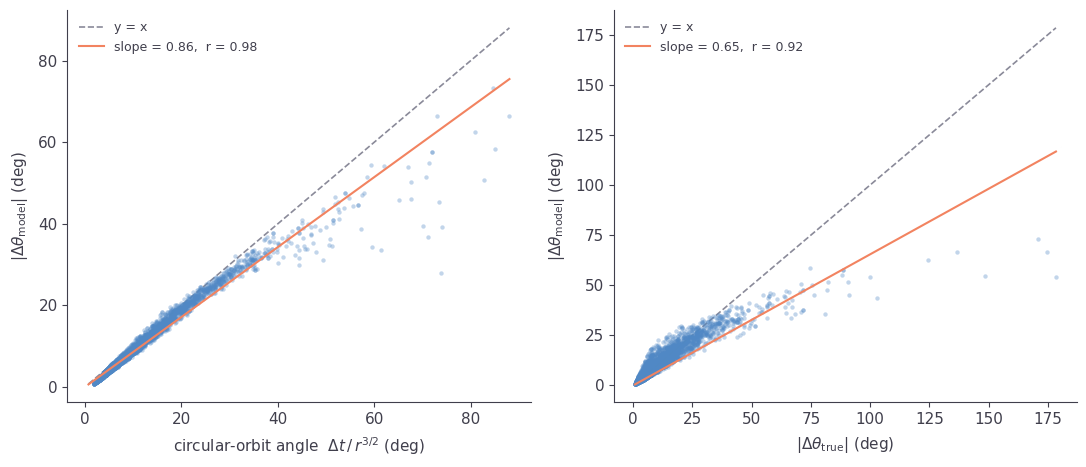

In [12]:
#| label: fig-circular
#| fig-cap: "Left: the model's per-step rotation angle against the angle a circular orbit of the same radius would sweep, dt / r^{3/2}. Right: the model's angle against the true orbital angle. Dashed lines are the identity; annotations give the fitted slope and correlation. Windows whose circular prediction exceeds 90 degrees are dropped."
#| code-fold: true
from analysis.elm import ARC_SLATE, ARC_VIBE, ARC_CORAL, ARC_DIAG

r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs, at_abs = np.abs(np.degrees(behav['ang_model'])), np.abs(np.degrees(behav['ang_true']))

mask = ang_circular < 90.0
ang_c_m, am_m, at_m = ang_circular[mask], am_abs[mask], at_abs[mask]
corr_m,   slope_m   = np.corrcoef(ang_c_m, am_m)[0, 1], np.polyfit(ang_c_m, am_m, 1)[0]
corr_beh, slope_beh = np.corrcoef(at_m,   am_m)[0, 1], np.polyfit(at_m,   am_m, 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
fig.subplots_adjust(wspace=0.38)

for ax, xdata, ydata, corr, slope, xlabel, title in [
    (axes[0], ang_c_m, am_m, corr_m, slope_m,
     r'circular-orbit angle  $\Delta t\,/\,r^{3/2}$ (deg)',
     r'model matches local circular orbit  (slope $\approx$ 1)'),
    (axes[1], at_m, am_m, corr_beh, slope_beh,
     r'$|\Delta\theta_{\text{true}}|$ (deg)',
     'vs. true orbital angle (departure = heuristic error)'),
]:
    lo = float(min(xdata.min(), ydata.min()))
    hi = float(max(xdata.max(), ydata.max()))
    xs = np.linspace(lo, hi, 100)

    # light grid
    ax.set_axisbelow(True)

    # reference lines
    ax.plot([lo, hi], [lo, hi], color=ARC_DIAG, lw=1.2,
            ls='--', label='y = x', zorder=1)
    ax.plot(xs, slope * xs, color=ARC_CORAL, lw=1.5,
            label=f'slope = {slope:.2f},  r = {corr:.2f}', zorder=3)

    # scatter
    ax.scatter(xdata, ydata, s=10, alpha=0.35,
               color=ARC_VIBE, linewidths=0, zorder=2)

    ax.set_xlabel(xlabel, labelpad=6)
    ax.set_ylabel(r'$|\Delta\theta_{\text{model}}|$ (deg)', labelpad=6)
    ax.legend(fontsize=9, frameon=False)

fig.tight_layout()
plt.show()


@fig-circular supports the circular rotation heuristic interpretation. The model's rotation angle tracks the circular-orbit prediction slightly better than the true orbital angle $\Delta t / r^{3/2}$ closely (left; corr $= 0.98$, $R^2 = 0.96$), deviating only at extreme angles likely near perihelion where large jumps in orbital position happen relative to time-slices used in our simulations. The fitted slope is $0.86$ rather than exactly $1$, so the heuristic lags a true circular orbit by roughly $14\%$. Compared to the true orbit angle (right), the model has a significantly reduced scaling (slope $= 0.65$), demonstrating that a local circular orbit matches the model's behaviour much closer than a properly fit elliptical orbit prediction.

So the noise-robust short-context model has almost certainly not learned Newtonian gravity. Instead, it has learned a local circular-orbit heuristic: rotate the most recent position by approximately the angle that a circular orbit of that radius would sweep out, while holding the radius mostly fixed. This is a smooth approximation that captures the $r^{-3/2}$ angular speed-up of a circular orbit but discards angular momentum and radial dynamics. This solution works in the context of the training task because the model is only ever trained to predict the position of one future timepoint (i.e. a rollout loss is not used), so a heuristic for a small time step can work reasonably well. The apparent noise-tolerance of this strategy is also a key as to why the model didn't (and probably *couldn't*) learn a Newtonian integrator, since solutions like Verlet will quadratically amplify input error. Could the model learn Verlet integration if noise were removed? We test this question in the next section.


## Without training noise the model learns a Newtonian world model

In the previous section, we established that the noisy short-context model settled for a smooth, noise-robust rotational heuristic. Naturally, we next wanted to ask if removing the denoising objective during training might allow the model to learn a more Newtonian solution. To test this, we repeat our analyses on a noiseless short-context model (`noise_scale = 0.0`). Freed from having to tolerate corrupted context, this model should be able to afford the sharp finite-difference computation of a genuine Newtonian force integrator. As before, our first test is to see if the content Jacobians isotropic coefficients settle near the inertial point.


In [13]:
#| code-fold: true
#| output: false
# Switch to the NOISELESS model (noise_scale = 0.0) and recompute its Jacobian blocks.
CKPT_BS2_NL = f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}_num_trajectories_{NUM_TRAJ}_noise_scale_0.0.pt'
with contextlib.redirect_stdout(io.StringIO()):
    model_noiseless, _ = load_from_checkpoint(CKPT_BS2_NL, device='cpu'); model_noiseless.eval()
    all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
        model_noiseless, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]; D = all_blocks.shape[-1]


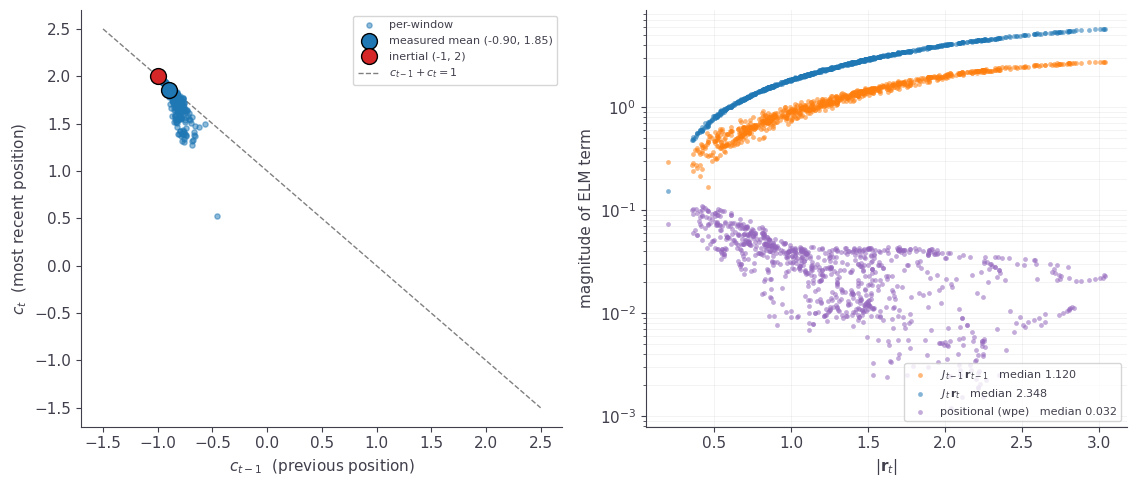

In [14]:
#| label: fig-verlet-noiseless
#| fig-cap: "Left: the noiseless short-context model in (c_{t-1}, c_t) space, with the same references as the noisy case: the inertial point (-1, 2) in red and the dashed line c_{t-1} + c_t = 1. Right: the magnitude of each of the three ELM terms for the same windows, against |r_t| on a log axis."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
NT.plot_coefficient_plane(axes[0], coeffs)

# Right panel: how big is each term in the ELM sum?  The coefficient analysis on
# the left uses the content Jacobians only, so show what the omitted positional
# term is worth alongside them.
NT.plot_term_magnitudes(axes[1], content, positional, radius)

fig.tight_layout()
plt.show()


@fig-verlet-noiseless shows the noiseless model's isotropic coefficients at $(c_{t-1}, c_t) \approx (-0.9, +1.85)$, much closer to the inertial point $(-1, 2)$ than the noisy model. This model seems to extrapolate forward like a genuine second-order integrator, rather than blending its two inputs. The absolute magnitudes of the ELM vector terms are also correspondingly changed. There's a consistent difference in the weighing of the two content terms that is relatively radius invariant, the most current positional term being weighed roughly twice as much as the previous positional term. Similar to the noisy model, the positional terms are relatively weak in magnitude, although we'll show later that they do make an important contribution to the final prediction.

The physics that should make this model explicitly Newtonian rather than merely inertial will live in the residual from the inertial point. In the next step, we verify behaviourally that this correction is exactly the Newtonian gravitational kick $-\Delta t^2\,\mathbf r_t/|\mathbf r_t|^3$, and then examine how that residual is organized across the model's two input tokens and positional embedding terms.


### The noiseless model captures the gravitational kick

As a first step, we behaviourally test (with no reference to the detached Jacobian) whether the model's non-inertial output actually captures Newtonian gravity. From the model's own second difference, $\mathbf a_{\text{eff}} = (\hat{\mathbf r}_{t+1} - 2\,\mathbf r_t + \mathbf r_{t-1})/\Delta t^2$, a genuine force integrator would give $\mathbf a_{\text{eff}} = -\mathbf r_t/|\mathbf r_t|^3$ ($GM=1$).


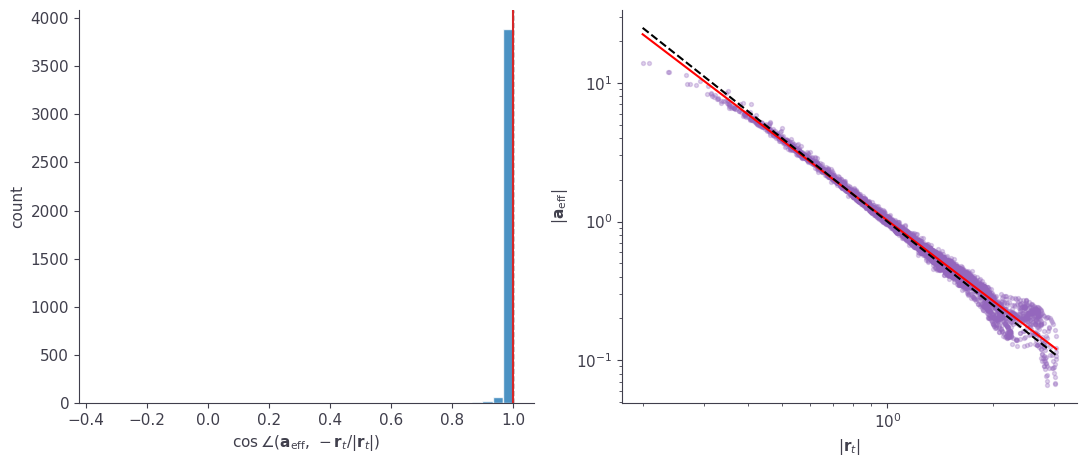

In [15]:
#| label: fig-newton-behavioral
#| fig-cap: "Behavioural test of the noiseless model's non-inertial output, computed from the model's own predictions with no reference to the Jacobian: a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1})/dt^2. Left: distribution of the cosine between a_eff and the sunward direction -r_t/|r_t|. Right: |a_eff| against |r_t| on log axes, with a fitted power law and the Newtonian 1/r^2 reference."
#| code-fold: true
# ── Behavioural acceleration test: is the model's non-inertial output Newtonian gravity? ──
# Attribution-free — uses the second difference of the model's OWN prediction, so it's
# invariant to how gravity is split across J_recent / J_prev:
#   a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1}) / dt^2     (Verlet: a_eff = -r_t/|r_t|^3, GM=1)
# Tests (1) does a_eff point at the focus?  (2) does |a_eff| ~ 1/r^2?
N_ACC = 4000
mdl   = model_noiseless                      # the noiseless (Verlet-like) model

w = NT.sample_orbit_windows(BLOCK_SIZE, N_ACC, seed=SEED, offset=OFFSET)   # (n,2,2)
r_prev, r_t = w[:, -2, :], w[:, -1, :]

mdtype = next(mdl.parameters()).dtype
with torch.no_grad():
    pred = mdl(torch.tensor(w).to(mdtype))[0][:, -1, :].double().numpy()   # (n,2)

a_eff  = (pred - 2*r_t + r_prev) / DT**2      # model's effective acceleration
r      = np.linalg.norm(r_t, axis=1)
a_true = -r_t / r[:, None]**3                 # Newtonian gravity at r_t (GM=1)

# (1) direction: cos between measured and Newtonian (focus-directed) acceleration
cos_dir = (a_eff*a_true).sum(1) / (np.linalg.norm(a_eff,axis=1)*np.linalg.norm(a_true,axis=1) + 1e-30)
# (2) magnitude scaling: |a_eff| ~ r^p; Newtonian p=-2, intercept -> GM
mag = np.linalg.norm(a_eff, axis=1)
slope, intercept = np.polyfit(np.log(r), np.log(mag), 1)
GM_est = np.exp(intercept)
# ── figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

ax = axes[0]
ax.hist(cos_dir, bins=40, color='tab:blue', alpha=0.8, edgecolor='white')
ax.axvline(1, color='k', ls='--', lw=1, label='perfect focus-directed')
ax.axvline(np.median(cos_dir), color='tab:red', lw=1.5, label=f'median {np.median(cos_dir):.2f}')
ax.set_xlabel(r'$\cos\angle(\mathbf{a}_{\text{eff}},\,-\mathbf{r}_t/|\mathbf{r}_t|)$'); ax.set_ylabel('count')

ax = axes[1]
ax.scatter(r, mag, s=8, alpha=0.3, color='tab:purple')
rr = np.linspace(r.min(), r.max(), 100)
ax.plot(rr, GM_est*rr**slope, 'r-',  lw=1.5, label=f'fit  p={slope:.2f}')
ax.plot(rr, rr**-2.0,         'k--', lw=1.5, label=r'Newtonian $1/r^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|\mathbf{r}_t|$'); ax.set_ylabel(r'$|\mathbf{a}_{\text{eff}}|$')

fig.tight_layout(); plt.show()


@fig-newton-behavioral confirms the model's effective acceleration points at the sun and scales inverse-square ($|\mathbf a_{\text{eff}}| \sim r^{-1.9}$ vs. Newtonian $r^{-2}$). Consequently, the noiseless model will functionally capture the angular momentum that the noisy model was blind to, correctly adjusting the predicted per-setp angle and radius change far more accurately (at least with no rollout loss, more on that below). Given we now know the gravitational kick is behaviourally present in this model, we next use the detached Jacobian to pinpoint how it is computed across the input components.


### What supplies the gravitational kick

The behavioural test tells us that the noiseless model's departure from inertial coasting matches Newtonian gravity. ELM however gives us the ability to go a step further and ask *how* that kick is produced by inspecting the terms the model actually adds up. Subtracting Verlet's inertial part from the content Jacobins in the ELM identity leaves three terms:

$$\underbrace{\hat{\mathbf r}_{t+1} - (2\,\mathbf r_t - \mathbf r_{t-1})}_{\text{deviation from inertia}} \;=\; \underbrace{\mathrm{d}J_t\,\mathbf r_t \;+\; \mathrm{d}J_{t-1}\,\mathbf r_{t-1}}_{\text{content residual}} \;+\; \underbrace{\mathbf P}_{\text{positional}}$$

with $\mathrm{d}J_t = J_t - 2I$, $\mathrm{d}J_{t-1} = J_{t-1} + I$, and $\mathbf P$ the positional term of the ELM identity. One term per input token plus the positional one.

Two features of the identity matter for what follows. First, it is a sum of vectors. The $\mathrm{d}J$ residual Jacobians are *operators*, and they only become contributions once they act on their inputs, so the three terms have to be compared as products $\mathrm{d}J\,\mathbf r$ rather than as matrices. Second, the positional term is not negligible at this scale. It is a couple of percent of the prediction (@fig-verlet-noiseless, right), but the deviation from inertia is itself some forty times smaller than the prediction, and measured against that quantity $\mathbf P$ is comparable in size to the gravitational kick. For simplicity in this section, we collapse both content residual terms ($\mathrm{d}J_t\,\mathbf r_t \;+\; \mathrm{d}J_{t-1}\,\mathbf r_{t-1}$) together (the same as our treatment of the positional embedding terms so far).


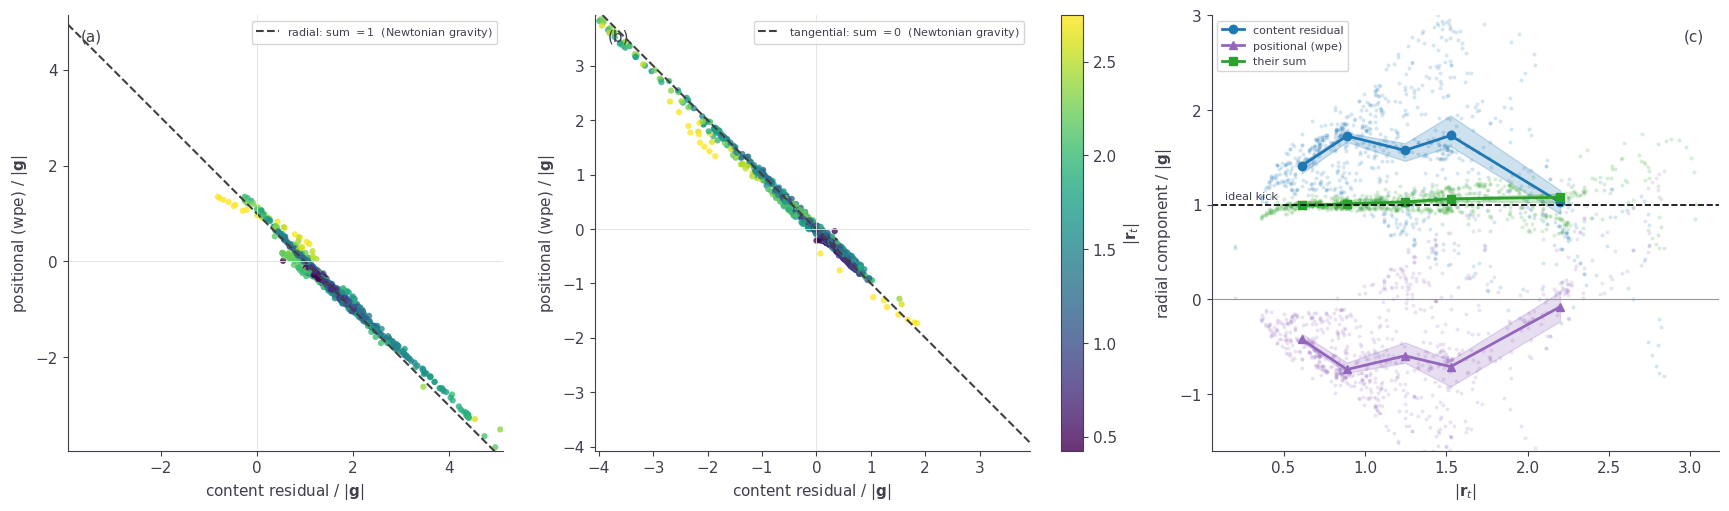

In [16]:
#| label: fig-kick-terms
#| fig-cap: "The noiseless model's deviation from inertial coasting, split into the content residual (dJ_t r_t + dJ_(t-1) r_(t-1)) and the positional term P. Panels (a) and (b) resolve that deviation in each window's own gravity frame, radial toward the star and tangential to it, and plot the positional contribution against the content one, both in units of |g|. Dashed lines mark where the pair sums to 1 (radial) and to 0 (tangential), as reproducing gravity requires. Points are coloured by |r_t|. Panel (c) plots the radial division against |r_t| directly, with medians over five quantile bins and 95% bootstrap confidence intervals of the median."
#| code-fold: true
from analysis.elm import kick_terms, plot_kick_terms

w_kick = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_kick) == len(all_blocks), f"{len(w_kick)} vs {len(all_blocks)}"

# The ELM identity is exact, so the three terms must reproduce the model's own
# deviation from inertial coasting. Check that rather than trust it -- it catches
# any index or sign slip in the dJ products.
_kt = kick_terms(content, positional, w_kick, DT)
_mdtype = next(model_noiseless.parameters()).dtype
with torch.no_grad():
    _pred = model_noiseless(torch.tensor(w_kick).to(_mdtype))[0][:, -1, :].double().numpy()
_inertia = 2 * w_kick[:, T - 1, :] - w_kick[:, T - 2, :]
assert np.abs(_kt['total'] - (_pred - _inertia)).max() < 1e-6

fig, axes = plt.subplots(1, 3, figsize=(17.4, 5.0), constrained_layout=True)
kick = plot_kick_terms(axes, content, positional, w_kick, DT)

plt.show()


@fig-kick-terms shows that both the content residuals and the positional embeddings are required to reconstruct the correct gravitational pull. Each panel resolves one component of the deviation in that window's own gravity frame, radial along the ideal kick (toward the star), and tangential (perpendicular error), and plots what each ELM term supplies. Gravity requires the radial pair to sum to $1$ and the tangential pair to sum to $0$, which puts each component on a line of slope $-1$; the dashed lines are those two constraints. Both components have points scattered across their lines, demonstrating how the combination of **all** terms is used to capture Newtonian gravity.

Radially, the content residual on average oversupplies roughly $1.5\times$ the required sunward pull, which is countered by the positional term, trimming the overshoot. Tangentially, where gravity should contribute nothing at all, each term carries a sizeable sideways push whose direction varies from window to window, and the two annihilate. Panel (c) plots the radial division against radius directly. Wherever $r<1$ the content residual consistently oversupplies the gravitational kick, which is countered by the positional embedding terms. At larger radii, ($r>1$), there is more variability in the contributions of the two types of terms, with the positional embedding at times contributing positively to boost an underpowered content residual kick, and in even rarer cases where the content residual contributes a negative (outward) radial pull.

So the gravitational kick is assembled by cancellation across the positional and content residual components. This final piece of the puzzle demonstrates that the model captures Newtonian gravity through different components across windows, highlighting the context-based nature of how the same underlying principles of the world model are actually enacted across inputs. 

The two residual operators thesmelves turn out to be near-negations of one another, $dJ_t + dJ_{t-1} \approx I$, so the local map is translation-equivariant; and each is a scaled rotation. We describe them below for interest.

:::  {.callout-note collapse="true" title="What the two residual operators look like (descriptive)"}

Here we highlight the structure of the content Jacobian deviations from inertia, $\mathrm{d}J_t = J_t - 2I$ and $\mathrm{d}J_{t-1} = J_{t-1} + I$.

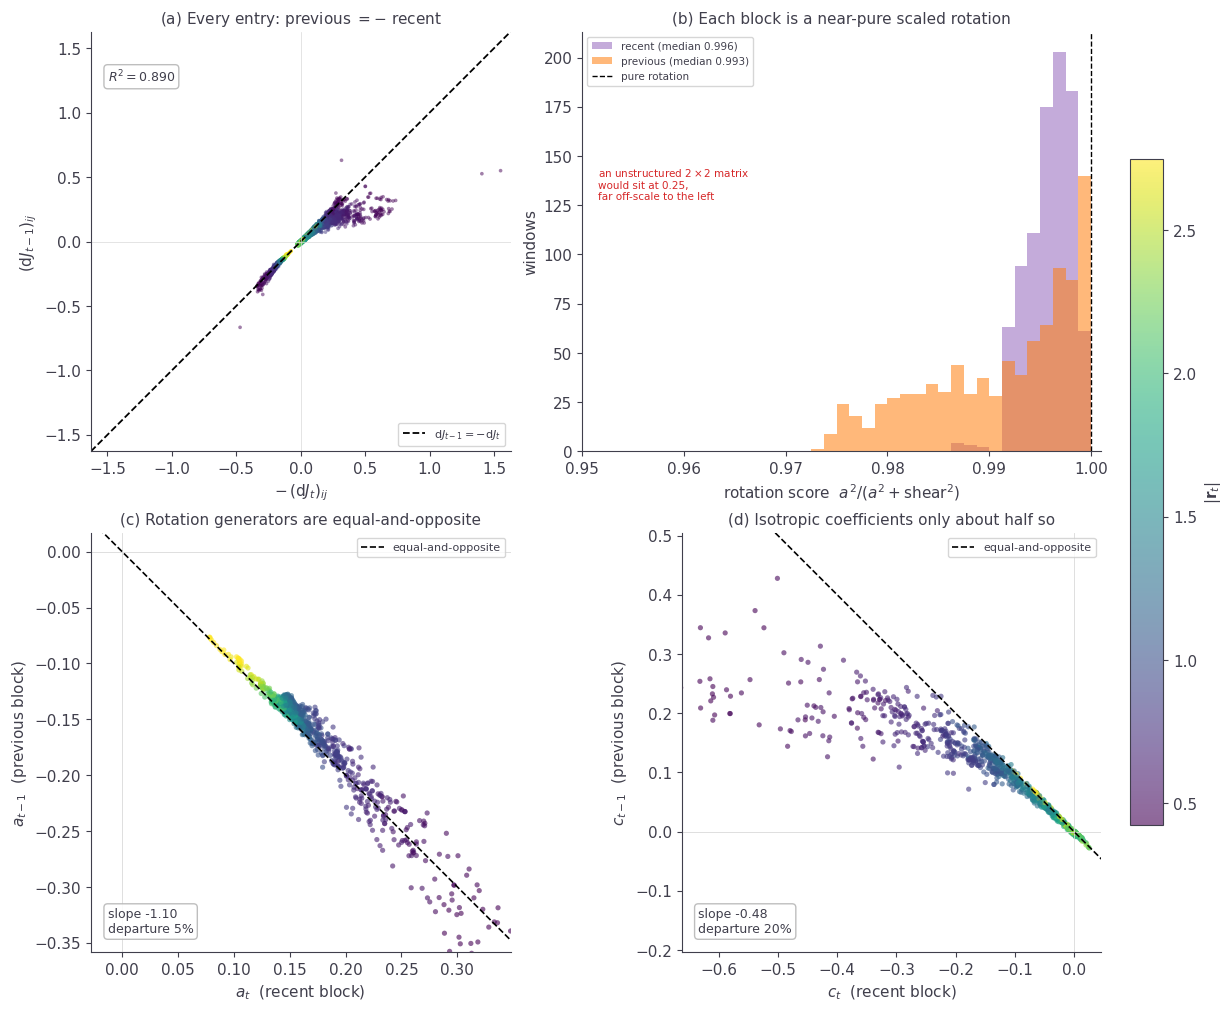

In [17]:
#| label: fig-residual-structure
#| fig-cap: "The two deviation-from-inertia operators of the noiseless short-context model, dJ_t = J_t - 2I and dJ_(t-1) = J_(t-1) + I, coloured throughout by |r_t|. (a) Every matrix entry of the previous block against the negative of the corresponding recent-block entry. (b) The rotation score a^2/(a^2 + shear^2) of each block, on a zoomed axis. (c) and (d) The rotation generator a and the isotropic coefficient c, previous block against recent. Each panel is scaled to its own cloud, so the fitted slope is annotated."
#| code-fold: true
from analysis.elm import plot_residual_structure

w_match = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_match) == len(all_blocks), f"{len(w_match)} vs {len(all_blocks)}"

fig, axes = plt.subplots(2, 2, figsize=(12.4, 10.0), constrained_layout=True)
st = plot_residual_structure(axes, all_blocks, w_match)

plt.show()


@fig-residual-structure characterises the two operators. An entry-wise comparison across pairs of $\mathrm{d}J_t , \mathrm{d}J_{t-1}$ shows a strong negational structure, with a deviation toward small radii. 

Panels (b), (c) and (d) describe the form of each operator. Both are scaled rotations: the rotation score exceeds $0.97$ in every window, against roughly $0.25$ for an unstructured $2\times2$ matrix, so shear is negligible and each block reduces to an isotropic scale $c$ composed with a rotation generator $a$. Those two coefficients do not behave alike across the pair. The rotation generator is equal-and-opposite to within about $5\%$ per window (fitted slope $-1.10$), whereas the isotropic coefficient is only about half so (slope $-0.48$, $20\%$), mostly due to a departure from anti-symmetry at small radii.

:::


## Why the mechanism matters: rolling out the two models

A correct one-step force is only useful if it integrates into a correct orbit over a longer time horizon. To see the practical consequence of computation strategies we identified in the two short-context models, we seed each model with the first two positions of a held-out orbit and let it predict autoregressively for 40 steps, feeding each prediction back as the next input. We plot the predicted orbits alongside an ideal Verlet integrator and the ground truth orbit.


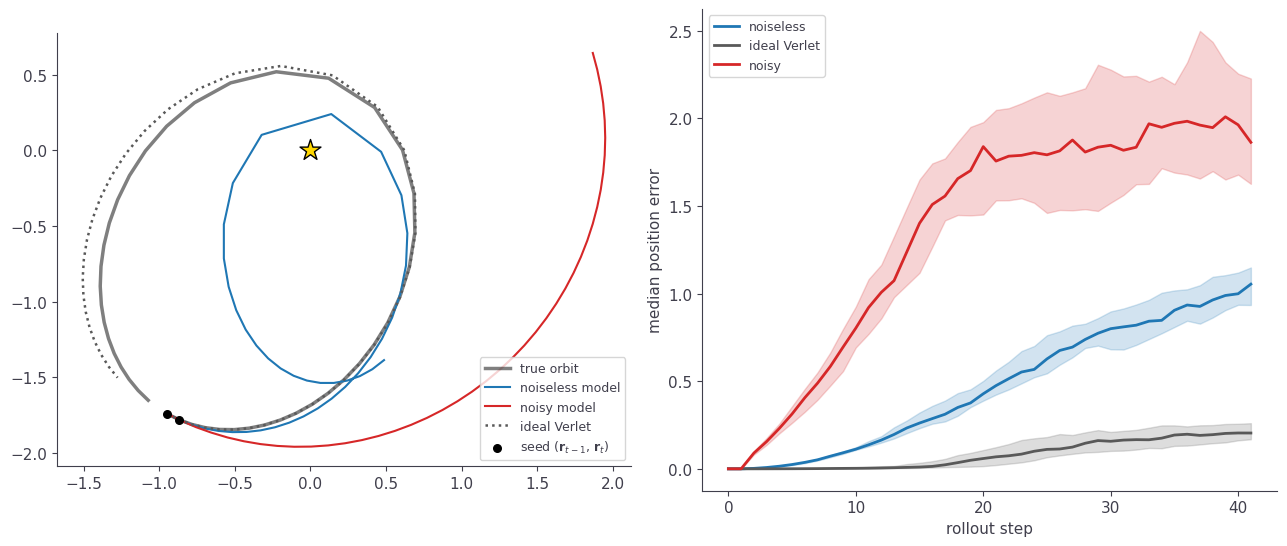

In [18]:
#| label: fig-rollout
#| fig-cap: "Autoregressive rollout on eccentric orbits (0.5 < e < 0.7), seeded from two consecutive positions and rolled forward 40 steps with each prediction fed back as the next input. Left: one example orbit seeded at aphelion, showing the true ellipse, an ideal Verlet integrator, and the two short-context models. Right: median position error against rollout step over 200 randomly drawn eccentric orbits seeded at random phase, with a 95% bootstrap confidence interval of the median. Ideal Verlet is integrated at the data's true sample spacing, dt = 20/99."
#| code-fold: true
from analysis.elm import rollout, rollout_verlet
from analysis.data import load_orbital_params

N            = 40
N_ORBITS     = 200
EXAMPLE_SEED = 0     # re-roll the single example orbit in the left panel

with contextlib.redirect_stdout(io.StringIO()):
    _tr = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=OFFSET + 2000))
    _op = load_orbital_params(DATA_DIR, num_trajectories_needed=OFFSET + 2000)
_e = np.array([p['e'] for p in _op])

# all eccentric orbits in the loaded (test-split) pool, then an UNBIASED random sample
ecc_all = [i for i in range(OFFSET, OFFSET + 2000) if 0.5 < _e[i] < 0.7]
rng     = np.random.default_rng(SEED)
sample  = rng.choice(ecc_all, size=min(N_ORBITS, len(ecc_all)), replace=False)
# Seed each rollout from a RANDOM phase along its orbit. Every trajectory is
# generated starting at perihelion, so seeding from tr[:2] would phase-lock all
# orbits at minimum radius and manufacture a spurious oscillation in the median.
offsets = rng.integers(0, 100 - (N + 2) + 1, size=len(sample))

errs = {'noiseless': [], 'ideal Verlet': [], 'noisy': []}
for i, k in zip(sample, offsets):
    tr = _tr[i]; s = tr[k:k+2]; truth = tr[k:k+N+2]
    errs['noiseless'].append(np.linalg.norm(rollout(model_noiseless, s, N)   - truth, axis=1))
    errs['ideal Verlet'].append(np.linalg.norm(rollout_verlet(s, N, dt=DT) - truth, axis=1))
    errs['noisy'].append(np.linalg.norm(rollout(model_bs2, s, N)             - truth, axis=1))
errs = {k: np.array(v) for k, v in errs.items()}
step = np.arange(N + 2)

# bootstrap 95% CI of the median error at each step
def median_ci(m, n_boot=2000, seed=0):
    r = np.random.default_rng(seed)
    n = m.shape[0]
    med = np.median(m, axis=0)
    idx = r.integers(0, n, size=(n_boot, n))          # resample orbits with replacement
    boot = np.median(m[idx], axis=1)                  # (n_boot, n_steps)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return med, lo, hi

# Example orbit: an independent random draw with its own RNG, so re-rolling the
# example (change EXAMPLE_SEED) leaves the error-curve sample untouched.
ex_rng = np.random.default_rng(EXAMPLE_SEED)
ei = int(ex_rng.choice(ecc_all))
true = _tr[ei]
# Start the example at APHELION -- the outermost point, found as the largest radius
# within the allowed start range. Like perihelion it has dr/dt = 0, so the rollout
# leaves the orbit smoothly and what stays visible is the heuristic's angular error
# rather than its radial one. Unlike perihelion it is also the *easiest* phase for a
# fixed-step integrator (slow motion, weak force): seeding at perihelion instead makes
# dt = 20/99 far too coarse for the 1/r^2 force there, and the ideal-Verlet reference
# itself takes a permanent energy hit, ending up less accurate than either model.
# The error curves on the right keep their random phases -- phase-locking those would
# manufacture a spurious oscillation in the median.
ek = int(np.argmax(np.linalg.norm(true[:100 - (N + 2) + 1], axis=1)))
s = true[ek:ek+2]; seg = true[ek:ek+N+2]
rn, rv, rx = rollout(model_noiseless, s, N), rollout_verlet(s, N, dt=DT), rollout(model_bs2, s, N)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
axA.plot(seg[:, 0], seg[:, 1], 'k-', lw=2.5, alpha=0.5, label='true orbit')
axA.plot(rn[:, 0], rn[:, 1], '-',  color='tab:blue', lw=1.5, label='noiseless model')
axA.plot(rx[:, 0], rx[:, 1], '-',  color='tab:red',  lw=1.5, label='noisy model')
axA.plot(rv[:, 0], rv[:, 1], ':',  color='0.35',     lw=1.8, label='ideal Verlet')
axA.scatter(0, 0, marker='*', s=250, color='gold', edgecolor='k', zorder=5)
axA.scatter(s[:, 0], s[:, 1], color='k', s=30, zorder=5,
            label=r'seed ($\mathbf{r}_{t-1}$, $\mathbf{r}_t$)')
axA.set_aspect('equal'); axA.legend(fontsize=9)

# right: MEDIAN error vs step over the random sample, with a 95% bootstrap CI band
for name, c in [('noiseless', 'tab:blue'), ('ideal Verlet', '0.35'), ('noisy', 'tab:red')]:
    med, lo, hi = median_ci(errs[name], seed=SEED)
    axB.plot(step, med, color=c, lw=2, label=name)
    axB.fill_between(step, lo, hi, color=c, alpha=0.2)
axB.set_xlabel('rollout step'); axB.set_ylabel('median position error')
axB.legend(fontsize=9)
fig.tight_layout(); plt.show()


@fig-rollout shows that the noiseless model tracks the true orbital ellipse well early in the rollout and then accumulates error as it proceeds, demonstrating that while it has learned an approximate one-step force, small per-step errors compound, and it never matches the accuracy of an ideal Verlet scheme, which stays closest to the truth throughout. The noisy model's local circular-orbit heuristic becomes obvious with just a few rollout steps, as it quite literally turns the ellipse into a circle, missing the true orbit from the very first steps. Its error is large but bounded, saturating as it settles onto a stable, wrong, circular path rather than diverging. This behaviour is further evident when plotting median error across many orbits. The Verlet integrator keeps error low across many rollout steps, the noiseless model tracks Verlet for 4-5 steps before accumulating error, while the noisy model rapidly gains error before plateauing in a stable, high error regime.


## Why the probe recovers force in both models
Linear probing reports the Newtonian force at $R^2 \approx 1.0$ in both short-context models (@fig-phase-transition), yet the two compute entirely different things: one integrates a force, the other turns the planet on a circle. A probe that cannot separate those two is reporting something other than the computation. What is it reading?

To probe this we investigated where the linear probes are drawing information from the models, and how this compares to the overall variance in their internal activation space. We focus on the final layernorm, the last representation before the output head. Taking its principal components over held-out windows we ask two things of each component in turn: how much of the activation variance does it carry, and how much does it add to a linear probe's ability to read $|\mathbf F|$? Components are ordered by variance, so the question is what is available in the directions the representation actually moves along.


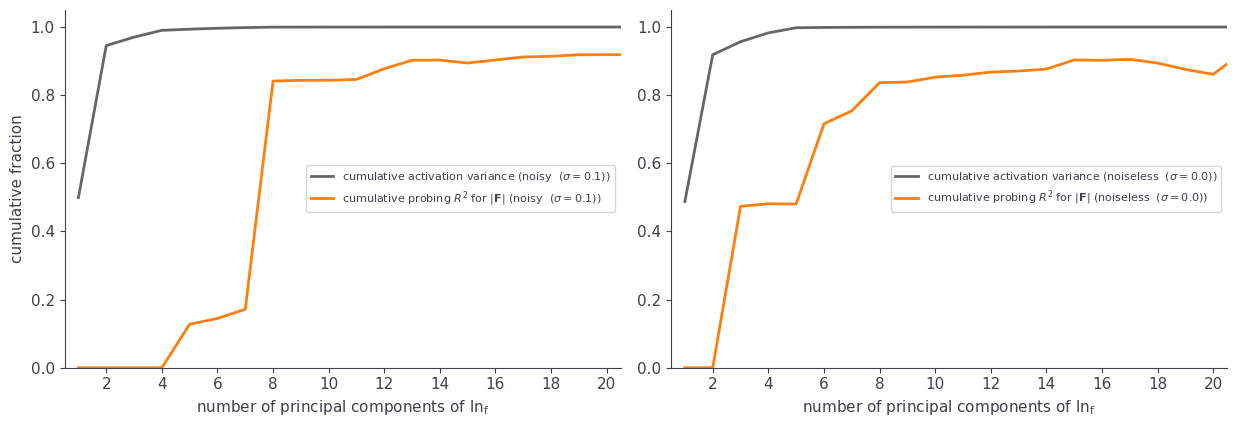

In [24]:
#| label: fig-scree-probe
#| fig-cap: "Activation variance and force decodability per principal component of the final layernorm, one panel per short-context model. Grey bars: the share of activation variance carried by each component. Orange bars: the gain in held-out probing R^2 for |F| when that component is added to the readout. Dotted line: cumulative variance. The annotation marks the component contributing the largest single gain in R^2."
#| code-fold: true
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

N_SUB = 4000
W_sub = NT.sample_orbit_windows(BLOCK_SIZE, N_SUB, seed=SEED, offset=OFFSET)
r_prev_s, r_t_s = W_sub[:, -2, :], W_sub[:, -1, :]
rad_s  = np.linalg.norm(r_t_s, axis=1)
grav_s = -r_t_s / rad_s[:, None] ** 3                 # true Newtonian acceleration, GM = 1
F_s    = 1.0 / rad_s ** 2
i_tr, i_te = train_test_split(np.arange(N_SUB), test_size=0.5, random_state=0)


def subspace_sweep(mdl):
    """Per k, everything this section needs from the top-k principal components of ln_f.

    The output head is linear and bias-free, so the prediction splits exactly and
    additively: y = W_head @ bulk_k + W_head @ tail_k (asserted below). Components
    are ordered by activation variance, never by usefulness for |F|.

    Returns  var   per-component share of activation variance
             r2    held-out probing R^2 for |F| from the top-k
             rho   fraction of the gravitational kick the bulk-only output reproduces,
                   1 - |a_bulk - g| / |g|, per window then median
    """
    rec = {}
    hk = mdl.transformer.ln_f.register_forward_hook(
        lambda m, i, o: rec.__setitem__('L', o.detach()[:, -1, :].double().clone()))
    try:
        with torch.no_grad():
            pred = mdl(torch.tensor(W_sub).to(next(mdl.parameters()).dtype))[0][:, -1, :]
    finally:
        hk.remove()
    L  = rec['L'].numpy()
    Wh = mdl.output_head.weight.detach().double().numpy()
    assert np.abs(L @ Wh.T - pred.double().numpy()).max() < 1e-10
    mu = L[i_tr].mean(0)
    _, S, Vt = np.linalg.svd(L[i_tr] - mu, full_matrices=False)
    P   = (L - mu) @ Vt.T
    var = S ** 2 / (S ** 2).sum()
    ng  = np.linalg.norm(grav_s, axis=1)
    r2, rho = [], []
    for k in range(1, L.shape[1] + 1):
        r2.append(r2_score(F_s[i_te],
                           LinearRegression().fit(P[i_tr][:, :k], F_s[i_tr])
                                             .predict(P[i_te][:, :k])))
        y_bulk = mu @ Wh.T + P[:, :k] @ (Vt[:k] @ Wh.T)
        a_bulk = (y_bulk - 2 * r_t_s + r_prev_s) / DT ** 2
        rho.append(np.median((1 - np.linalg.norm(a_bulk - grav_s, axis=1) / ng)[i_te]))
    return dict(var=var, cum=np.cumsum(var), r2=np.array(r2), rho=np.array(rho))


SUB = {'noisy  ($\\sigma=0.1$)':     subspace_sweep(model_bs2),
       'noiseless  ($\\sigma=0.0$)': subspace_sweep(model_noiseless)}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=False)
for ax, (name, d) in zip(axes, SUB.items()):
    ks  = np.arange(1, len(d['var']) + 1)

    ax.plot(ks, d['cum'], color='0.4', lw=2,
            label=f'cumulative activation variance ({name})')
    ax.plot(ks, np.clip(d['r2'], 0, None), color='tab:orange', lw=2,
            label=r'cumulative probing $R^2$ for $|\mathbf{F}|$' + f' ({name})')

    ax.set_xlabel('number of principal components of $\\mathrm{ln_f}$')
    ax.set_xlim(0.5, 20.5)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(np.arange(2, 21, 2))
    ax.legend(fontsize=8, loc='center right')

axes[0].set_ylabel('cumulative fraction')
fig.tight_layout()
plt.show()

@fig-scree-probe shows that the activations in the final layernorm are low rank in both models with the first two principal components carrying over 90% of the variance. Conversely, the linear probe force readouts are decoded from the long, low variance dimension tail. In the noisy model the majority of the readout arrives with component 8 while in the noiseless model the single largest gain occurs earlier at component 3. That the probe uses low variance dimensions is not necessarily an issue in and of itself. The gravitational kick is usually much smaller in scale than inertia, therefore it being encoded in low variance dimensions does not strictly mean that it is not used in the final prediction. We can test this question more explicitly by ablating dimensions from the final layernorm output and observing their effect on the predicted shift away from inertia (which we previously established as capturing gravity in the noiseless model).  

Split the representation into the **bulk**, the leading $k$ components carrying the majority of the variance, and the **tail**, everything else. Because the output head is linear and bias-free, the prediction splits with it, exactly and additively:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{W_{\text{head}}\,\ell_{\le k}}_{y_{\text{bulk}}} \;+\; \underbrace{W_{\text{head}}\,\ell_{>k}}_{y_{\text{tail}}}$$

so we can ask what the model still computes from the bulk alone. Taking the effective acceleration of the bulk-only prediction exactly as in @fig-newton-behavioral, we score it against true gravity as the fraction of the kick reproduced,

$$\rho \;=\; 1 - \frac{|\,\mathbf a_{\text{bulk}} - \mathbf g\,|}{|\,\mathbf g\,|}$$

which is 1 when the kick exactly matches gravity in direction and magnitude, 0 when the bulk output is no better than having no kick at all, and negative when it is worse than omitting gravity altogether.

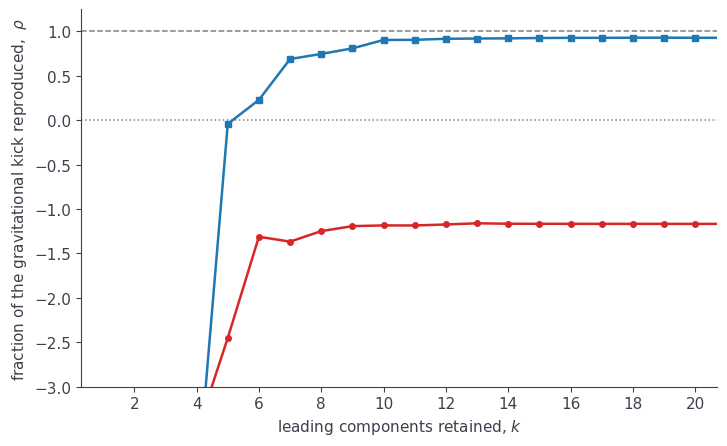

In [28]:
#| label: fig-bulk-tail
#| fig-cap: "Fraction of the gravitational kick reproduced by the bulk-only prediction, against the number of leading principal components retained. rho = 1 - |a_bulk - g|/|g|, taken per window then median: 1 is the kick reproduced exactly, 0 is no better than having no kick at all, and negative is worse than omitting gravity altogether. Shading marks the bulk, the leading components carrying 99% of the activation variance. Points below the axis limit at small k are off scale."
#| code-fold: true
fig, ax = plt.subplots(figsize=(7.4, 4.6))
K99 = max(int(np.searchsorted(d['cum'], 0.99) + 1) for d in SUB.values())
ax.axhline(1, color='0.5', ls='--', lw=1.1, zorder=1)
ax.axhline(0, color='0.5', ls=':',  lw=1.1, zorder=1)
for (name, d), colour, marker in zip(SUB.items(), ('tab:red', 'tab:blue'), ('o', 's')):
    ks = np.arange(1, len(d['rho']) + 1)
    ax.plot(ks, d['rho'], marker + '-', color=colour, ms=4, lw=1.8, label=name, zorder=3)
ax.set_xlim(0.3, 20.7); ax.set_ylim(-3.0, 1.25); ax.set_xticks(np.arange(2, 21, 2))
ax.set_xlabel('leading components retained, $k$')
ax.set_ylabel(r'fraction of the gravitational kick reproduced,  $\rho$')
fig.tight_layout(); plt.show()


@fig-bulk-tail shows that the noisy model never approaches one at any $k$ and therefore never captures the expected gravitational kick. No subspace of its representation yields an output that reproduces gravity, because its output is primarily rotation. In the noiseless model the gravitational kick emerges appreceably only above $k = 7$, further along that we would predict with the linear probe results. 

So the two models differ not in *where* their fine structure sits but in what that structure does. Both decode force from the tail but in one the tail also supplies the kick, in the other it does not. This result echoes previous analyses which have established that decodability of a variable is not an indication of use (CITATIOn). This is further reinforced by our results in the noiseless model which we know explicitly uses Newtonian force to calculate its predictions. Even here, linear probes suggest that force should emerge in earlier principal components than what we observe in practice, highlighting the disconnect between decodability and utilization. 

## Conclusions 

By combining ELM and a battery of behavioural tests we show that the short-context model trained by Liu et al. has not learned a Newtonian world model, despite the linear decodability of Newtonian force components observed via linear probing. Rather, it runs a radius based rotational heuristic, rotating the most recent positional input by roughly the angle a circular orbit of that radius would sweep and holding the radius nearly fixed. The key to forcing a Newtonian world model in this setting turns out to be the removal of input noise during training. Liu et al. benchmarked noise addition for a much longer context length model (50 input positions). In this setting, with a long tail of seen positions, noise is indeed beneficial for stabilizing model rollout as established by the authors. However our own rollout experiments with short-context models have shown that noise is actively harmful when few input positions are available for efficient input denoising. Critically, input noise is strongly detrimental to the desired “true” world model in this system since a genuine second order integrator will quadratically amplify input noise, resulting in poor performance. It is therefore unsurprising that we observed a strong shift in the internal computation strategy of the short-context model when we removed noise during training, bringing the final model much closer to learning a true Newtonian representation of the system. 

Inspecting the internal computation of a network, or running behavioural tests alone is not enough to establish the learned world model. There exist an infinite number of linear combinations of input positions that can accurately predict the next planetary position in an orbit. Our solution to this problem is to define the world model based on an expected analytical solution which is directly derived from Newton’s laws, the Verlet integrator. This reference requires inertia to be captured in the two positions the model receives as input, providing a constraint on the content Jacobians which allow us to quantify world model state. However, while undoubtedly our results suggest that the noiseless short context model gets very close to capturing inertia in the content Jacobians, the additional input term provided by the positional embedding still means we do not recover a unique global computation strategy. Rather, the gravitational kick seems to be encoded in a complex way among both the positional embedding Jacobian and the content Jacobians, including cancellation among them. Because of the degrees of freedom provided by these two terms, different runs of this model will undoubtedly differ both in how gravity is computed among these terms, but also in how close the content Jacobians get to the inertial point; the more unnecessary cancellation exists among the two term types, the further the computation will drift from the intertial point. In light of this, we posit that viewing learned world models from the lens of a continuous distribution is likely more useful than assigning strict states. In this way we can more confidently say that the noiseless short-context model has learned a *more* Newtonian world model compared to the noisy model, albeit with variation between input windows and model replicates.  

Our use of a reference solution as a baseline has the advantage of being unambiguous, but it is not the usual one in the world model literature, and it comes with clear limits. It requires an analytic ground-truth computation to compare against and a map simple enough to read, two constraints that are often not available: in natural language there is no Verlet to point to, and even here the long-context model was too complex for us to interpret its ELM readouts, which is why we restricted the mechanistic analysis to the two-token model. We have also varied only two context lengths, one architecture, and a single 2D orbital domain, so we take the continuum picture as a worked demonstration rather than a general law. 
